In [9]:
import pandas as pd

df = pd.read_csv("Supermart Grocery Sales - Retail Analytics Dataset (1).csv")

print("Dimensions :", df.shape)
display(df.head())
df.info()


df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    dayfirst=True
)

print(df["Order Date"].dtype)



print("Valeurs manquantes :")
print(df.isnull().sum())

print("\nLignes dupliquées :", df.duplicated().sum())


display(df.describe())

Dimensions : (9994, 11)


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,11-08-2017,North,1254,0.12,401.28,Tamil Nadu
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,11-08-2017,South,749,0.18,149.80,Tamil Nadu
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,06-12-2017,West,2360,0.21,165.20,Tamil Nadu
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,10-11-2016,South,896,0.25,89.60,Tamil Nadu
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,10-11-2016,South,2355,0.26,918.45,Tamil Nadu


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   object 
 1   Customer Name  9994 non-null   object 
 2   Category       9994 non-null   object 
 3   Sub Category   9994 non-null   object 
 4   City           9994 non-null   object 
 5   Order Date     9994 non-null   object 
 6   Region         9994 non-null   object 
 7   Sales          9994 non-null   int64  
 8   Discount       9994 non-null   float64
 9   Profit         9994 non-null   float64
 10  State          9994 non-null   object 
dtypes: float64(2), int64(1), object(8)
memory usage: 859.0+ KB
datetime64[ns]
Valeurs manquantes :
Order ID         0
Customer Name    0
Category         0
Sub Category     0
City             0
Order Date       0
Region           0
Sales            0
Discount         0
Profit           0
State            0
dtype: int64

,Order Date,Sales,Discount,Profit
count,9994,9994.000000,9994.000000,9994.000000
mean,2017-04-11 12:33:42.973784064,1496.596158,0.226817,374.937082
min,2015-01-02 00:00:00,500.000000,0.100000,25.250000
25%,2016-05-01 00:00:00,1000.000000,0.160000,180.022500
50%,2017-05-30 00:00:00,1498.000000,0.230000,320.780000
75%,2018-04-09 00:00:00,1994.750000,0.290000,525.627500
max,2018-12-30 00:00:00,2500.000000,0.350000,1120.950000
std,NaN,577.559036,0.074636,239.932881


In [3]:
print("Valeurs manquantes :")
print(df.isnull().sum())

print("Lignes dupliquées :", df.duplicated().sum())

Valeurs manquantes :
Order ID         0
Customer Name    0
Category         0
Sub Category     0
City             0
Order Date       0
Region           0
Sales            0
Discount         0
Profit           0
State            0
dtype: int64
Lignes dupliquées : 0


In [10]:
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())

Total Sales: 14956982
Total Profit: 3747121.1999999997


In [11]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Sales=("Sales", "mean"),
    Number_of_Orders=("Order ID", "nunique")
)

display(category_analysis.sort_values("Total_Sales", ascending=False))

,Total_Sales,Total_Profit,Average_Sales,Number_of_Orders
Category,,,,
"Eggs, Meat & Fish",2267401,567357.22,1521.745638,1490
Snacks,2237546,568178.85,1477.903567,1514
Food Grains,2115272,529162.64,1513.070100,1398
Bakery,2112281,528521.06,1494.891012,1413
Fruits & Veggies,2100727,530400.38,1481.471791,1418
Beverages,2085313,525605.76,1489.509286,1400
Oil & Masala,2038442,497895.29,1497.753123,1361


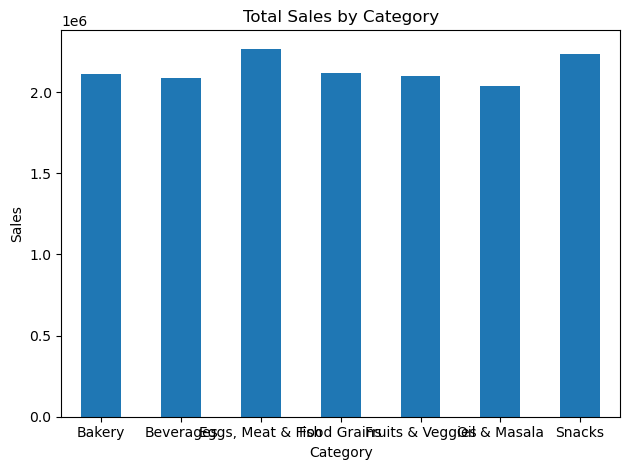

In [12]:
import matplotlib.pyplot as plt

category_analysis["Total_Sales"].plot(
    kind="bar",
    title="Total Sales by Category",
    ylabel="Sales",
    xlabel="Category"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
    * 100
)

display(
    category_analysis.sort_values(
        "Profit_Margin",
        ascending=False
    ).round(2)
)


,Total_Sales,Total_Profit,Average_Sales,Number_of_Orders,Profit_Margin
Category,,,,,
Snacks,2237546,568178.85,1477.90,1514,25.39
Fruits & Veggies,2100727,530400.38,1481.47,1418,25.25
Beverages,2085313,525605.76,1489.51,1400,25.21
"Eggs, Meat & Fish",2267401,567357.22,1521.75,1490,25.02
Bakery,2112281,528521.06,1494.89,1413,25.02
Food Grains,2115272,529162.64,1513.07,1398,25.02
Oil & Masala,2038442,497895.29,1497.75,1361,24.43
